## Check for similiarity in datasets

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer, util

EXPGUARD = "../../data_ood_translated/expguard_finance_test_de.jsonl"
POLYGUARD = "../../data_ood_translated/polyguard_finance_test_de.jsonl"
TEST  = "../../data_in/test.jsonl"


expguard = pd.read_json(EXPGUARD, lines=True)
polyguard = pd.read_json(POLYGUARD, lines=True)
v3 = pd.read_json(TEST, lines=True)

datasets = {
    "v3 (Test)": v3,
    "ExpGuard":  expguard,
    "PolyGuard": polyguard,
}

,count,mean,std,min,25%,50%,75%,max
dataset,,,,,,,,
ExpGuard,964.0,24.7,19.9,6.0,13.0,19.0,28.0,145.0
PolyGuard,994.0,97.4,35.6,37.0,71.0,88.0,117.0,276.0
v3 (Test),2447.0,49.4,82.9,1.0,10.0,24.0,56.0,913.0


prompt_label,safe,unsafe
dataset,,
ExpGuard,18.0,19.0
PolyGuard,71.0,116.0
v3 (Test),23.0,24.5


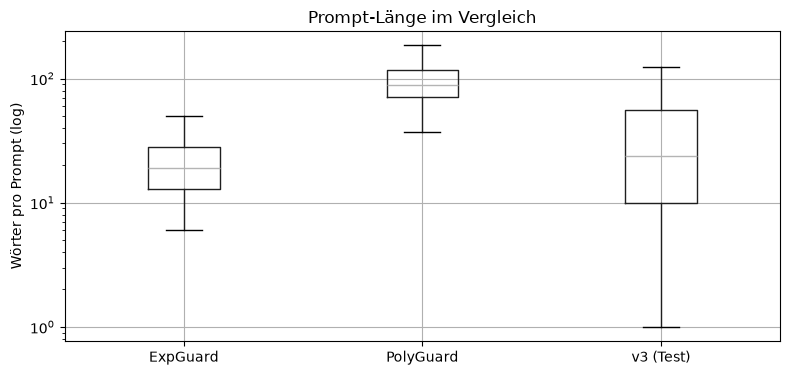

In [6]:
frames = []
for name, df in datasets.items():
    d = df[["prompt", "prompt_label"]].copy()
    d = d[d["prompt"].notna() & (d["prompt"].str.strip() != "") & (d["prompt"] != "REDACTED")]
    d["dataset"] = name
    d["zeichen"] = d["prompt"].str.len()
    d["woerter"] = d["prompt"].str.split().str.len()
    frames.append(d)

laengen = pd.concat(frames, ignore_index=True)

# Kennzahlen pro Datensatz
display(laengen.groupby("dataset")["woerter"].describe(percentiles=[.25, .5, .75]).round(1))

# Median getrennt nach Label
display(laengen.groupby(["dataset", "prompt_label"])["woerter"].median().unstack())

# Boxplot
fig, ax = plt.subplots(figsize=(8, 4))
laengen.boxplot(column="woerter", by="dataset", ax=ax, showfliers=False)
ax.set_yscale("log")
ax.set_ylabel("Wörter pro Prompt (log)")
ax.set_xlabel("")
ax.set_title("Prompt-Länge im Vergleich")
plt.suptitle("")
plt.tight_layout()
plt.show()

In [7]:
model = SentenceTransformer("sentence-transformers/paraphrase-multilingual-mpnet-base-v2")

In [8]:
def encode(texts):
    return model.encode(texts.tolist(), batch_size=32, convert_to_tensor=True,
                        normalize_embeddings=True, show_progress_bar=True)

emb_v3  = encode(v3["prompt"])
emb_exp = encode(expguard["prompt"])
emb_pol = encode(polyguard["prompt"])

def nn_sim(query, reference, exclude_self=False):
    """Für jeden Query-Prompt: Ähnlichkeit zum ähnlichsten Referenz-Prompt."""
    sims = util.cos_sim(query, reference)
    if exclude_self:
        sims.fill_diagonal_(-1)   # sich selbst nicht als nächsten Nachbarn zählen
    return sims.max(dim=1).values.cpu().numpy()

v3["nn_sim"]        = nn_sim(emb_v3, emb_v3, exclude_self=True)   # ID-Referenz
expguard["nn_sim"]  = nn_sim(emb_exp, emb_v3)
polyguard["nn_sim"] = nn_sim(emb_pol, emb_v3)

vergleich = pd.DataFrame({
    "v3 (ID)":   v3["nn_sim"].describe(),
    "ExpGuard":  expguard["nn_sim"].describe(),
    "PolyGuard": polyguard["nn_sim"].describe(),
}).round(3)
display(vergleich)

Batches: 100%|██████████| 32/32 [00:04<00:00,  6.69it/s]


,v3 (ID),ExpGuard,PolyGuard
count,2447.000,964.000,994.000
mean,0.682,0.593,0.588
std,0.100,0.070,0.057
min,0.329,0.360,0.441
25%,0.618,0.544,0.547
50%,0.677,0.588,0.588
75%,0.739,0.643,0.625
max,1.000,0.817,0.777


In [11]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

ergebnisse = []
for name, df in [("ExpGuard", expguard), ("PolyGuard", polyguard)]:
    id_werte  = v3["nn_sim"].to_numpy()
    ood_werte = df["nn_sim"].to_numpy()

    # 1) Mann-Whitney-U: Liegen die v3-Werte systematisch höher?
    _, p = mannwhitneyu(id_werte, ood_werte, alternative="greater")

    # 2) AUROC: Wie gut trennt die Ähnlichkeit v3 (=1) von OOD (=0)?
    y      = np.r_[np.ones(len(id_werte)), np.zeros(len(ood_werte))]
    scores = np.r_[id_werte, ood_werte]
    auroc  = roc_auc_score(y, scores)

    ergebnisse.append({"Datensatz": name, "Median OOD": np.median(ood_werte),
                       "p-Wert": p, "AUROC": auroc})

display(pd.DataFrame(ergebnisse).round({"Median OOD": 3, "AUROC": 3}))

,Datensatz,Median OOD,p-Wert,AUROC
0,ExpGuard,0.588,0.0,0.771
1,PolyGuard,0.588,0.0,0.800
